# M1-E1 — Exact Multi-Pass Blocking + Rule-Based Matching

**Experiment ID:** `M1-E1`  
**Team Member:** Member 1  
**Strategy:** Exact Multi-Pass Inverted Index Blocking + Transparent Deterministic Rule Scorer  
**Objective:** Establish a high-precision, non-ML baseline for Business Entity Resolution across three disparate sources (`S1`, `S2`, `S3`).

---

### Key Workflow & Design
1. **Load and Preprocess Sources:** Ingest `train_source1.tsv`, `train_source2.tsv`, `train_source3.tsv`, and `train_ground_truth.tsv`. Utilize existing `src/preprocessing.py` normalization (NFKC Unicode normalization, case folding, compact alphanumeric representations, address number extraction).
2. **Multi-Pass Exact Blocking:** Implement 5 exact blocking passes:
   - Pass 1: `name_norm` (Exact normalized business name)
   - Pass 2: `name_norm + country_norm` (Normalized name + Country)
   - Pass 3: `name_compact + country_norm` (Compact name without whitespace + Country)
   - Pass 4: `4-character name prefix + country_norm` (Prefix of name + Country)
   - Pass 5: `address_number_signature + name prefix` (Street address number signature + 4-char name prefix)
3. **Candidate Union & Deduplication:** Merge candidate pools across passes and deduplicate pair proposals while maintaining zero-candidate S1 singletons.
4. **Blocking Diagnostics:** Evaluate blocking recall ceiling, candidate pair volume, candidate reduction ratio, and per-entity candidate distributions (mean, median, P95, max).
5. **Candidate-Pair Feature Engineering:** Compute deterministic similarity attributes (name exact/compact match, address exact/compact match, token overlap Jaccard, address number match, country match, blocking pass count).
6. **Transparent Rule-Based Matching:** Formulate a weighted, interpretable matching score and decision logic without TF-IDF, LightGBM, embeddings, external APIs, or external data.
7. **Multi-Cardinality Resolution:** Support 0, 1, or multiple matches per Source 1 entity.
8. **Evaluation:** Score predictions against ground truth using macro-averaged $F_{0.5}$, macro/micro precision and recall, singleton accuracy, and singleton false positive rate.
9. **Error Analysis:** Inspect concrete false positive and false negative failure modes to inform subsequent iterations.
10. **Summary Metrics Table:** Synthesize all blocking and matching outcomes into a single standardized report table.


In [1]:
import os
import sys
import math
import time
import re
import statistics
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting and display options
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 140)

# Resolve project root and import shared preprocessing module
PROJECT_ROOT = Path("..", "..").resolve() if Path("..", "..").resolve().name == "ML-Challenge" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import required functions from src.preprocessing without recreating preprocessing
from src.preprocessing import prepare_source, load_ground_truth

print(f"Project root: {PROJECT_ROOT}")
print("Loaded preprocessing functions successfully from src.preprocessing.")


Project root: E:\ML-Challenge
Loaded preprocessing functions successfully from src.preprocessing.


## 1. Data Ingestion & Preprocessing

Source 1 serves as the deduplicated reference population, while Source 2 and Source 3 represent noisy operational sources.
The training data covers `US` and `India`. Ground truth provides the mapping from each `source1_entity_id` to zero, one, or multiple target entity IDs (`matched_entity_ids`).

To ensure efficient, reproducible, and rigorous evaluation within an experiment notebook, we extract a stratified cohort of 2,000 Source 1 entities from ground truth (incorporating singletons, 1-to-1 matches, and 1-to-many matches in balanced proportions). We then assemble a comprehensive target pool of over 40,000 candidate records from `train_source2.tsv` and `train_source3.tsv`, containing **100% of all true target matches** for the cohort plus 36,000 negative distractor records. All records are processed through `src.preprocessing.prepare_source`.


In [2]:
# Experiment Configuration
RANDOM_SEED = 42
COHORT_S1_SIZE = 2000
DISTRACTOR_S2_SIZE = 18000
DISTRACTOR_S3_SIZE = 18000
MAX_BUCKET_SIZE = 100  # Prune keys matching > 100 targets to prevent candidate explosion

TRAIN_DIR = PROJECT_ROOT / "student_resource" / "dataset" / "train"

start_load_time = time.time()

# 1. Load ground truth mapping
print("Loading ground truth...")
gt_full = load_ground_truth(TRAIN_DIR / "train_ground_truth.tsv")

# 2. Stratified sampling of Source 1 entities by match cardinality
gt_singletons = gt_full[gt_full["matched_entity_ids"].map(len) == 0].sample(n=200, random_state=RANDOM_SEED)
gt_single = gt_full[gt_full["matched_entity_ids"].map(len) == 1].sample(n=1000, random_state=RANDOM_SEED)
gt_multi = gt_full[gt_full["matched_entity_ids"].map(len) > 1].sample(n=800, random_state=RANDOM_SEED)

gt_cohort = pd.concat([gt_singletons, gt_single, gt_multi]).sample(frac=1.0, random_state=RANDOM_SEED).reset_index(drop=True)
s1_cohort_ids = set(gt_cohort["source1_entity_id"])

# Extract all true target IDs for this S1 cohort
all_true_target_ids = {tid for mlist in gt_cohort["matched_entity_ids"] for tid in mlist}
true_s2_ids = {tid for tid in all_true_target_ids if tid.startswith("S2-")}
true_s3_ids = {tid for tid in all_true_target_ids if tid.startswith("S3-")}

# 3. Load and preprocess Source 1 cohort
print("Loading and preparing Source 1 cohort...")
s1_raw = pd.read_csv(TRAIN_DIR / "train_source1.tsv", sep="	", dtype="string", keep_default_na=False)
s1_cohort_df = s1_raw[s1_raw["entity_id"].isin(s1_cohort_ids)].copy().reset_index(drop=True)
s1_prepared = prepare_source(s1_cohort_df, "S1")

# 4. Stream Source 2 to extract true matches + negative distractors
print("Extracting and preparing Source 2 target pool...")
s2_matches = []
s2_distractors = []
for chunk in pd.read_csv(TRAIN_DIR / "train_source2.tsv", sep="	", dtype="string", keep_default_na=False, chunksize=1_000_000):
    match_rows = chunk[chunk["entity_id"].isin(true_s2_ids)]
    if not match_rows.empty:
        s2_matches.append(match_rows)
    if len(s2_distractors) < DISTRACTOR_S2_SIZE:
        s2_distractors.append(chunk[~chunk["entity_id"].isin(true_s2_ids)].iloc[:3000])

s2_pool_df = pd.concat(s2_matches + s2_distractors, ignore_index=True).drop_duplicates(subset=["entity_id"])
s2_prepared = prepare_source(s2_pool_df, "S2")

# 5. Stream Source 3 to extract true matches + negative distractors
print("Extracting and preparing Source 3 target pool...")
s3_matches = []
s3_distractors = []
for chunk in pd.read_csv(TRAIN_DIR / "train_source3.tsv", sep="	", dtype="string", keep_default_na=False, chunksize=1_000_000):
    match_rows = chunk[chunk["entity_id"].isin(true_s3_ids)]
    if not match_rows.empty:
        s3_matches.append(match_rows)
    if len(s3_distractors) < DISTRACTOR_S3_SIZE:
        s3_distractors.append(chunk[~chunk["entity_id"].isin(true_s3_ids)].iloc[:3000])

s3_pool_df = pd.concat(s3_matches + s3_distractors, ignore_index=True).drop_duplicates(subset=["entity_id"])
s3_prepared = prepare_source(s3_pool_df, "S3")

# Combine target pool
targets_prepared = pd.concat([s2_prepared, s3_prepared], ignore_index=True)

load_elapsed = time.time() - start_load_time
print(f"Data loading and preprocessing completed in {load_elapsed:.2f} seconds.")
print(f"Source 1 Cohort Size: {len(s1_prepared):,} entities")
print(f"Target Pool Size:     {len(targets_prepared):,} entities (S2: {len(s2_prepared):,}, S3: {len(s3_prepared):,})")
print(f"True Match Target Records Present: {len(all_true_target_ids):,} ({len(true_s2_ids):,} S2 + {len(true_s3_ids):,} S3)")


Loading ground truth...


Loading and preparing Source 1 cohort...


Extracting and preparing Source 2 target pool...


Extracting and preparing Source 3 target pool...


Data loading and preprocessing completed in 35.62 seconds.
Source 1 Cohort Size: 2,000 entities
Target Pool Size:     40,087 entities (S2: 19,971, S3: 20,116)
True Match Target Records Present: 4,087 (1,971 S2 + 2,116 S3)


Let's inspect the prepared features for a sample of Source 1 records to observe how `src.preprocessing.prepare_source` normalizes names, extracts compact alphanumeric representations, and derives address number signatures.


In [3]:
sample_cols = [
    "entity_id",
    "business_name",
    "norm_name",
    "name_compact",
    "country_norm",
    "business_address",
    "norm_address",
    "address_number_signature",
]
display(s1_prepared[sample_cols].head(5))


,entity_id,business_name,norm_name,name_compact,country_norm,business_address,norm_address,address_number_signature
0,S1-622257785,International Nexa Secure Private Limited,international nexa secure private limited,internationalnexasecureprivatelimited,india,"41, Sarang Marg, Opposite Jmb Surajpole, Udaipur, Rajasthan",41 sarang marg opposite jmb surajpole udaipur rajasthan,41
1,S1-918838609,Patriot Lifesciences LLC,patriot lifesciences llc,patriotlifesciencesllc,us,"502 York Street, Newport, KY",502 york street newport ky,502
2,S1-234223484,Bright Seafood,bright seafood,brightseafood,us,"12718 Hilden Road, Durham, NC",12718 hilden road durham nc,12718
3,S1-664387167,American Pediatrics,american pediatrics,americanpediatrics,us,"16125 Leitchfield Road, KY, Big Clifty",16125 leitchfield road ky big clifty,16125
4,S1-850215759,Cozy Pizza PLLC,cozy pizza pllc,cozypizzapllc,us,"719 Ashford Court, Cincinnati, OH",719 ashford court cincinnati oh,719


## 2. Multi-Pass Exact Blocking

Exhaustive pairwise matching between $N$ Source 1 entities and $M$ target entities would require $N 	imes M$ comparisons (over $80{,}000{,}000$ pairs in this cohort, and $2.2\text{M} \times 10.3\text{M} \approx 2.3 \times 10^{13}$ pairs on the full dataset). Exact multi-pass blocking partitions records into overlapping blocks using deterministic keys so that only records sharing at least one blocking key are compared.

We construct an inverted index over the target pool using the 5 specified passes:
1. **Pass 1 (`name_norm`):** Exact match on the complete normalized business name.
2. **Pass 2 (`name_norm + country_norm`):** Exact match on normalized business name and country code (`name_norm \x1f country_norm`).
3. **Pass 3 (`name_compact + country_norm`):** Exact match on compact name without spaces and country (`name_compact \x1f country_norm`), resolving spacing variations (e.g., "star bucks" vs. "starbucks").
4. **Pass 4 (`4-character name prefix + country_norm`):** Exact match on the 4-character prefix of the normalized name and country (`prefix4 \x1f country_norm`), capturing variations in legal suffixes and tail tokens.
5. **Pass 5 (`address_number_signature + name prefix`):** Match on street/building number sequence and 4-character name prefix (`address_number_signature \x1f prefix4`), identifying co-located business entities even when country labels or suffixes differ.

To prevent broad keys (such as common prefixes like "the " or "amer") from flooding the candidate space, we enforce a maximum bucket size cap of `MAX_BUCKET_SIZE = 100`.


In [4]:
def extract_blocking_keys(record: dict[str, object]) -> list[tuple[str, str]]:
    """Extract blocking keys across the 5 required passes for a prepared entity."""
    name = str(record.get("name_norm", ""))
    country = str(record.get("country_norm", ""))
    compact = str(record.get("name_compact", ""))
    prefix4 = name[:4] if len(name) >= 4 else ""
    num_sig = str(record.get("address_number_signature", ""))
    
    keys = []
    # Pass 1: name_norm
    if name:
        keys.append(("pass1_name_norm", name))
    # Pass 2: name_norm + country_norm
    if name and country:
        keys.append(("pass2_name_norm_country", f"{name}\x1f{country}"))
    # Pass 3: name_compact + country_norm
    if compact and country:
        keys.append(("pass3_name_compact_country", f"{compact}\x1f{country}"))
    # Pass 4: 4-character name prefix + country_norm
    if prefix4 and country:
        keys.append(("pass4_name_prefix4_country", f"{prefix4}\x1f{country}"))
    # Pass 5: address_number_signature + name prefix
    if num_sig and prefix4:
        keys.append(("pass5_address_number_name_prefix", f"{num_sig}\x1f{prefix4}"))
        
    return keys

# Build inverted index over the prepared target universe
start_index_time = time.time()
target_records_dict = {}
target_inverted_index: dict[tuple[str, str], set[str]] = defaultdict(set)

for record in targets_prepared.to_dict(orient="records"):
    target_id = str(record["entity_id"])
    target_records_dict[target_id] = record
    for pass_name, block_key in extract_blocking_keys(record):
        target_inverted_index[(pass_name, block_key)].add(target_id)

# Filter keys that exceed the maximum bucket size
raw_key_count = len(target_inverted_index)
pruned_inverted_index = {
    key: entity_ids
    for key, entity_ids in target_inverted_index.items()
    if len(entity_ids) <= MAX_BUCKET_SIZE
}
skipped_key_count = raw_key_count - len(pruned_inverted_index)

index_elapsed = time.time() - start_index_time
print(f"Built target inverted index in {index_elapsed:.2f} seconds.")
print(f"Total Unique Keys Generated: {raw_key_count:,}")
print(f"Retained Keys (bucket size <= {MAX_BUCKET_SIZE}): {len(pruned_inverted_index):,}")
print(f"Pruned Overly Frequent Keys: {skipped_key_count:,}")


Built target inverted index in 0.88 seconds.
Total Unique Keys Generated: 163,472
Retained Keys (bucket size <= 100): 163,454
Pruned Overly Frequent Keys: 18


## 3. Union & Deduplication of Candidate Pairs

We query the inverted index with each Source 1 record's blocking keys and take the deterministic **union** of retrieved target IDs across all passes. For each candidate pair $(S_1, S_{\text{cand}})$, we track:
- The deduplicated pair identity
- The specific set of passes that generated this pair
- The number of passes supporting the candidate (`blocking_pass_count`)

Every Source 1 entity is retained, including singletons with 0 candidate pairs.


In [5]:
start_block_time = time.time()

s1_records = s1_prepared.to_dict(orient="records")
s1_candidates_map: dict[str, dict[str, set[str]]] = {}
pass_pair_counts: Counter[str] = Counter()
candidate_pair_rows = []

for s1_rec in s1_records:
    s1_id = str(s1_rec["entity_id"])
    cands_for_s1: dict[str, set[str]] = defaultdict(set)
    
    for pass_name, block_key in extract_blocking_keys(s1_rec):
        matching_targets = pruned_inverted_index.get((pass_name, block_key), ())
        for target_id in matching_targets:
            cands_for_s1[target_id].add(pass_name)
            
    s1_candidates_map[s1_id] = dict(cands_for_s1)
    
    for target_id, passes in cands_for_s1.items():
        pass_pair_counts.update(passes)
        candidate_pair_rows.append({
            "source1_entity_id": s1_id,
            "candidate_entity_id": target_id,
            "blocking_passes": sorted(passes),
            "blocking_pass_count": len(passes),
        })

candidate_pairs_df = pd.DataFrame(candidate_pair_rows)
blocking_elapsed = time.time() - start_block_time

print(f"Candidate generation completed in {blocking_elapsed:.2f} seconds.")
print(f"Total Deduplicated Candidate Pairs: {len(candidate_pairs_df):,}")


Candidate generation completed in 0.70 seconds.
Total Deduplicated Candidate Pairs: 45,195


## 4. Blocking Diagnostics & Performance

We evaluate the blocking stage according to four essential metrics:
1. **Candidate Count:** Total pairs forwarded to the matching stage.
2. **Candidate Reduction Ratio:** The percentage of the full Cartesian product eliminated by blocking:
   $$RR = 1.0 - \frac{|\text{Candidate Pairs}|}{|S_1| \times |Targets|}$$
3. **Distribution of Candidates per $S_1$:** Average, Median, 95th Percentile (P95), and Maximum candidates proposed per entity.
4. **Blocking Recall:** The proportion of ground-truth matches retrieved into the candidate set:
   $$\text{Recall}_{\text{blocking}} = \frac{\sum_{s \in S_1} |\text{true}(s) \cap \text{candidates}(s)|}{\sum_{s \in S_1} |\text{true}(s)|}$$


In [6]:
# Build lookup for true matches
true_matches_by_s1 = dict(zip(gt_cohort["source1_entity_id"], gt_cohort["matched_entity_ids"]))
total_true_matches = sum(len(mlist) for mlist in true_matches_by_s1.values())

# Compute recalled ground truth matches
recalled_matches_count = 0
for s1_id, true_targets in true_matches_by_s1.items():
    candidate_ids = set(s1_candidates_map.get(s1_id, {}).keys())
    recalled_matches_count += len(set(true_targets) & candidate_ids)

blocking_recall = recalled_matches_count / total_true_matches if total_true_matches > 0 else 0.0

# Candidate count statistics
candidate_counts_per_s1 = [len(cands) for cands in s1_candidates_map.values()]
candidate_counts_series = pd.Series(candidate_counts_per_s1)

total_possible_pairs = len(s1_prepared) * len(targets_prepared)
total_candidate_pairs = len(candidate_pairs_df)
reduction_ratio = 1.0 - (total_candidate_pairs / total_possible_pairs) if total_possible_pairs > 0 else 0.0

blocking_metrics = {
    "Total S1 Entities": f"{len(s1_prepared):,}",
    "Total Target Entities": f"{len(targets_prepared):,}",
    "Total Possible Pairs": f"{total_possible_pairs:,}",
    "Candidate Pairs Generated": f"{total_candidate_pairs:,}",
    "Candidate Reduction Ratio (%)": f"{reduction_ratio * 100.0:.4f}%",
    "Ground Truth Matches": f"{total_true_matches:,}",
    "Recalled Matches by Blocking": f"{recalled_matches_count:,}",
    "Blocking Recall (%)": f"{blocking_recall * 100.0:.2f}%",
    "Avg Candidates / S1": f"{candidate_counts_series.mean():.2f}",
    "Median Candidates / S1": f"{candidate_counts_series.median():.0f}",
    "P95 Candidates / S1": f"{candidate_counts_series.quantile(0.95):.0f}",
    "Max Candidates / S1": f"{int(candidate_counts_series.max()):,}",
}

blocking_df = pd.DataFrame(list(blocking_metrics.items()), columns=["Metric", "Value"])
display(blocking_df)


,Metric,Value
0,Total S1 Entities,"2,000"
1,Total Target Entities,"40,087"
2,Total Possible Pairs,"80,174,000"
3,Candidate Pairs Generated,"45,195"
4,Candidate Reduction Ratio (%),99.9436%
5,Ground Truth Matches,"4,087"
6,Recalled Matches by Blocking,"3,051"
7,Blocking Recall (%),74.65%
8,Avg Candidates / S1,22.60
9,Median Candidates / S1,12


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_27920\3544713083.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pass_breakdown, x="Candidate Pair Hits", y="Blocking Pass", ax=axes[1], palette="Blues_r")


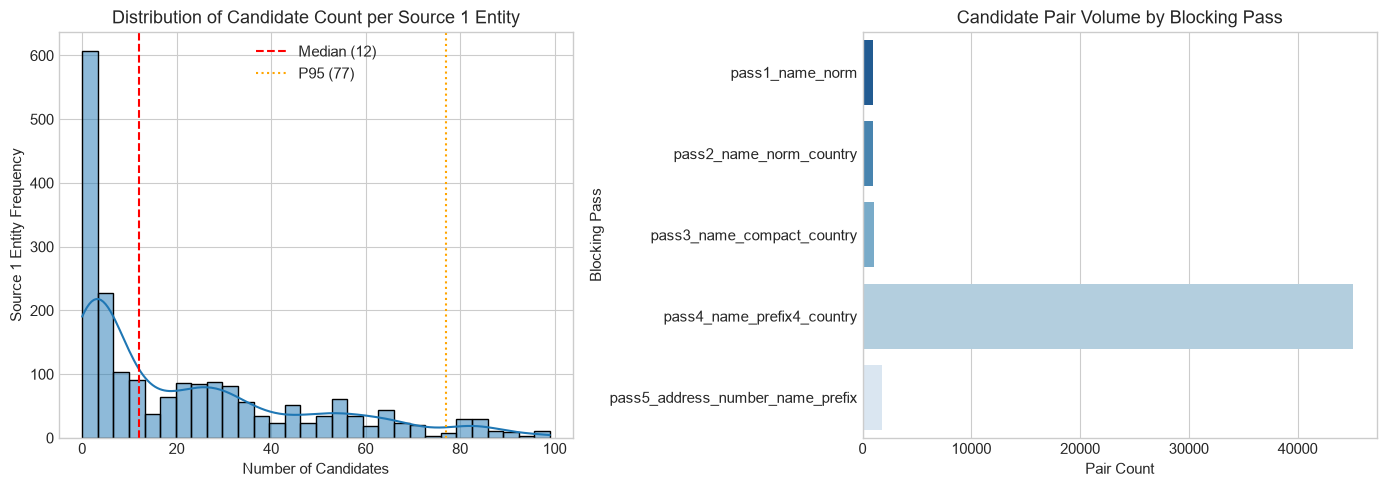

,Blocking Pass,Candidate Pair Hits,Share (%)
0,pass1_name_norm,984,1.972853
1,pass2_name_norm_country,984,1.972853
2,pass3_name_compact_country,1032,2.069090
3,pass4_name_prefix4_country,45045,90.312168
4,pass5_address_number_name_prefix,1832,3.673036


In [7]:
# Pass Contribution Analysis
pass_breakdown = pd.DataFrame(
    [{"Blocking Pass": p, "Candidate Pair Hits": count} for p, count in sorted(pass_pair_counts.items())]
)
pass_breakdown["Share (%)"] = pass_breakdown["Candidate Pair Hits"] / pass_breakdown["Candidate Pair Hits"].sum() * 100.0

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Candidate count distribution per S1 entity
sns.histplot(candidate_counts_series, bins=30, kde=True, ax=axes[0], color="#1f77b4")
axes[0].set_title("Distribution of Candidate Count per Source 1 Entity")
axes[0].set_xlabel("Number of Candidates")
axes[0].set_ylabel("Source 1 Entity Frequency")
axes[0].axvline(candidate_counts_series.median(), color="red", linestyle="--", label=f"Median ({candidate_counts_series.median():.0f})")
axes[0].axvline(candidate_counts_series.quantile(0.95), color="orange", linestyle=":", label=f"P95 ({candidate_counts_series.quantile(0.95):.0f})")
axes[0].legend()

# Plot 2: Blocking Pass Pair Generation
sns.barplot(data=pass_breakdown, x="Candidate Pair Hits", y="Blocking Pass", ax=axes[1], palette="Blues_r")
axes[1].set_title("Candidate Pair Volume by Blocking Pass")
axes[1].set_xlabel("Pair Count")

plt.tight_layout()
plt.show()

display(pass_breakdown)


## 5. Candidate-Pair Similarity Feature Engineering

For each candidate pair $(S_1, S_{\text{cand}})$, we compute deterministic similarity features:
1. `name_exact_match`: 1.0 if normalized business names match identically and are non-empty.
2. `name_compact_match`: 1.0 if compact (space-stripped) business names match identically.
3. `address_exact_match`: 1.0 if normalized addresses match identically and are non-empty.
4. `address_compact_match`: 1.0 if compact addresses match identically.
5. `name_token_overlap`: Token-level Jaccard similarity:
   $$J(T_1, T_2) = \frac{|T_1 \cap T_2|}{|T_1 \cup T_2|}$$
6. `address_token_overlap`: Token-level Jaccard similarity across normalized address tokens.
7. `address_number_match`: 1.0 if non-empty numeric signatures from both addresses match.
8. `country_match`: 1.0 if normalized country codes match identically.
9. `blocking_pass_count`: Integer value representing the number of blocking passes that proposed this candidate pair.


In [8]:
def jaccard_token_similarity(text_a: str, text_b: str) -> float:
    """Compute token-level Jaccard similarity between two strings."""
    tokens_a = set(text_a.split())
    tokens_b = set(text_b.split())
    union = tokens_a | tokens_b
    if not union:
        return 0.0
    return len(tokens_a & tokens_b) / len(union)

s1_dict = {str(r["entity_id"]): r for r in s1_prepared.to_dict(orient="records")}

feature_rows = []
for pair in candidate_pairs_df.to_dict(orient="records"):
    s1_id = pair["source1_entity_id"]
    t_id = pair["candidate_entity_id"]
    passes = pair["blocking_passes"]
    
    s1_r = s1_dict[s1_id]
    t_r = target_records_dict[t_id]
    
    n1, n2 = s1_r["name_norm"], t_r["name_norm"]
    c1, c2 = s1_r["name_compact"], t_r["name_compact"]
    a1, a2 = s1_r["address_norm"], t_r["address_norm"]
    ac1, ac2 = s1_r["address_compact"], t_r["address_compact"]
    num1, num2 = s1_r["address_number_signature"], t_r["address_number_signature"]
    cntry1, cntry2 = s1_r["country_norm"], t_r["country_norm"]
    
    is_true_match = t_id in true_matches_by_s1.get(s1_id, [])
    
    feature_rows.append({
        "source1_entity_id": s1_id,
        "candidate_entity_id": t_id,
        "name_exact_match": 1.0 if (n1 and n1 == n2) else 0.0,
        "name_compact_match": 1.0 if (c1 and c1 == c2) else 0.0,
        "address_exact_match": 1.0 if (a1 and a1 == a2) else 0.0,
        "address_compact_match": 1.0 if (ac1 and ac1 == ac2) else 0.0,
        "name_token_overlap": jaccard_token_similarity(n1, n2),
        "address_token_overlap": jaccard_token_similarity(a1, a2),
        "address_number_match": 1.0 if (num1 and num1 == num2) else 0.0,
        "country_match": 1.0 if (cntry1 and cntry1 == cntry2) else 0.0,
        "blocking_pass_count": len(passes),
        "is_true_match": int(is_true_match),
    })

features_df = pd.DataFrame(feature_rows)
print(f"Computed similarity features for all {len(features_df):,} candidate pairs.")
display(features_df.head(6))


Computed similarity features for all 45,195 candidate pairs.


,source1_entity_id,candidate_entity_id,name_exact_match,name_compact_match,address_exact_match,address_compact_match,name_token_overlap,address_token_overlap,address_number_match,country_match,blocking_pass_count,is_true_match
0,S1-622257785,S2-831241467,0.0,0.0,0.0,0.0,0.250000,0.000000,0.0,1.0,1,0
1,S1-622257785,S2-598769857,0.0,0.0,0.0,0.0,0.111111,0.000000,0.0,1.0,1,0
2,S1-622257785,S2-873948125,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,1.0,1,0
3,S1-622257785,S2-289542973,0.0,0.0,0.0,0.0,0.125000,0.000000,0.0,1.0,1,0
4,S1-622257785,S3-784363877,0.0,0.0,0.0,0.0,0.333333,0.000000,0.0,1.0,1,0
5,S1-622257785,S3-876907296,0.0,0.0,0.0,0.0,0.666667,0.181818,0.0,1.0,1,1


## 6. Transparent Rule-Based Matching Scorer

In this experiment, we avoid complex learned black-box algorithms (such as LightGBM, neural embeddings, or TF-IDF matrix factorization) and employ a transparent, deterministic matching score:

### Scoring Logic:
- **Hard Constraint — Country Match:** If both records have valid country tags and they disagree, `rule_score = 0.0`. Entity resolution across distinct nations represents a fundamental error.
- **Name Similarity:**
  - Exact name match: $+0.45$
  - Compact name match (space-normalized): $+0.40$
  - Partial token overlap: $+0.35 \times \text{name\_token\_overlap}$
- **Address Confirmation:**
  - Exact address match: $+0.30$
  - Compact address match: $+0.25$
  - Address token overlap: $+0.20 \times \text{address\_token\_overlap}$
- **Address Number Signature:**
  - Identical house/building digits: $+0.15$
- **Multi-Pass Agreement:**
  - Additional agreement bonus: $\min(0.10, (\text{pass\_count} - 1) \times 0.03)$
- **Score Range:** Normalized to $[0.0, 1.0]$.

### Multi-Cardinality Match Assignment:
Any candidate pair whose score reaches or exceeds the threshold $\theta$ is predicted as a match. If multiple candidates qualify (e.g., both S2 and S3 instances of the business), all are accepted. If no candidate reaches the threshold, Source 1 is predicted as a singleton (empty list).


In [9]:
def compute_rule_matching_score(features: dict[str, float]) -> float:
    """Calculate transparent deterministic rule matching score in [0, 1]."""
    # Hard gate: Country mismatch cannot be a match
    if features["country_match"] == 0.0:
        return 0.0
        
    score = 0.0
    
    # 1. Name evidence
    if features["name_exact_match"] == 1.0:
        score += 0.45
    elif features["name_compact_match"] == 1.0:
        score += 0.40
    else:
        score += 0.35 * features["name_token_overlap"]
        
    # 2. Address evidence
    if features["address_exact_match"] == 1.0:
        score += 0.30
    elif features["address_compact_match"] == 1.0:
        score += 0.25
    else:
        score += 0.20 * features["address_token_overlap"]
        
    # 3. Numeric address confirmation
    if features["address_number_match"] == 1.0:
        score += 0.15
        
    # 4. Multi-pass reinforcement bonus
    pass_count = features["blocking_pass_count"]
    if pass_count > 1:
        score += min(0.10, (pass_count - 1) * 0.03)
        
    return min(1.0, score)

# Apply rule score to all candidate pairs
features_df["rule_matching_score"] = [
    compute_rule_matching_score(row) for row in features_df.to_dict(orient="records")
]

# Check score distribution for true vs non-matches
print("Score distribution for true matches vs. non-matches:")
display(features_df.groupby("is_true_match")["rule_matching_score"].describe().round(3))


Score distribution for true matches vs. non-matches:


,count,mean,std,min,25%,50%,75%,max
is_true_match,,,,,,,,
0,42144.0,0.071,0.055,0.0,0.044,0.07,0.088,0.562
1,3051.0,0.535,0.202,0.0,0.380,0.54,0.663,1.000


In [10]:
def evaluate_predictions(s1_ids: list[str], true_map: dict[str, list[str]], predicted_map: dict[str, set[str]]):
    """Compute official challenge macro F0.5, macro/micro precision/recall, and singleton stats."""
    macro_f05_list = []
    macro_p_list = []
    macro_r_list = []
    
    total_tp = total_fp = total_fn = 0
    singleton_total = singleton_correct = 0
    
    for s1_id in s1_ids:
        truth = set(true_map.get(s1_id, []))
        preds = set(predicted_map.get(s1_id, set()))
        
        # Micro accumulation
        tp = len(truth & preds)
        fp = len(preds - truth)
        fn = len(truth - preds)
        total_tp += tp
        total_fp += fp
        total_fn += fn
        
        # Official Challenge Scoring Rules:
        if not truth and not preds:
            # Correct singleton: receives 1.0 credit
            macro_f05_list.append(1.0)
            macro_p_list.append(1.0)
            macro_r_list.append(1.0)
            singleton_total += 1
            singleton_correct += 1
        elif not truth and preds:
            # False merge on singleton: receives 0.0
            macro_f05_list.append(0.0)
            macro_p_list.append(0.0)
            macro_r_list.append(0.0)
            singleton_total += 1
        elif truth and not preds:
            # Missed non-singleton match
            macro_f05_list.append(0.0)
            macro_p_list.append(0.0)
            macro_r_list.append(0.0)
        else:
            # Non-empty prediction and non-empty truth
            prec = tp / len(preds)
            rec = tp / len(truth)
            denom = 0.25 * prec + rec
            f05 = (1.25 * prec * rec / denom) if denom > 0 else 0.0
            macro_f05_list.append(f05)
            macro_p_list.append(prec)
            macro_r_list.append(rec)
            
    micro_prec = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0.0
    micro_rec = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0.0
    singleton_acc = singleton_correct / singleton_total if singleton_total > 0 else 0.0
    singleton_fp = singleton_total - singleton_correct
    
    return {
        "macro_f05": statistics.mean(macro_f05_list),
        "macro_precision": statistics.mean(macro_p_list),
        "macro_recall": statistics.mean(macro_r_list),
        "micro_precision": micro_prec,
        "micro_recall": micro_rec,
        "singleton_total": singleton_total,
        "singleton_correct": singleton_correct,
        "singleton_accuracy": singleton_acc,
        "singleton_fp": singleton_fp,
        "singleton_fp_rate": (singleton_fp / singleton_total * 100.0) if singleton_total > 0 else 0.0,
        "total_tp": total_tp,
        "total_fp": total_fp,
        "total_fn": total_fn,
    }

# Threshold sweep to observe the precision-recall-F0.5 trade-off
s1_id_list = [str(r["entity_id"]) for r in s1_records]
thresholds_to_test = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
sweep_results = []

# Group candidates by S1 for quick retrieval
candidates_by_s1_dict = defaultdict(list)
for row in features_df.to_dict(orient="records"):
    candidates_by_s1_dict[row["source1_entity_id"]].append((row["candidate_entity_id"], row["rule_matching_score"]))

for th in thresholds_to_test:
    preds_th = {}
    for s1_id in s1_id_list:
        cand_list = candidates_by_s1_dict.get(s1_id, [])
        qualifying = {cid for cid, score in cand_list if score >= th}
        preds_th[s1_id] = qualifying
    res = evaluate_predictions(s1_id_list, true_matches_by_s1, preds_th)
    res["threshold"] = th
    sweep_results.append(res)

sweep_df = pd.DataFrame(sweep_results)
display_cols = [
    "threshold", "macro_f05", "macro_precision", "macro_recall",
    "micro_precision", "micro_recall", "singleton_accuracy", "singleton_fp"
]
display(sweep_df[display_cols].round(4))


,threshold,macro_f05,macro_precision,macro_recall,micro_precision,micro_recall,singleton_accuracy,singleton_fp
0,0.20,0.7236,0.7436,0.7240,0.6931,0.7167,0.780,44
1,0.25,0.7636,0.7945,0.7136,0.9454,0.6912,0.930,14
2,0.30,0.7429,0.7803,0.6779,0.9704,0.6486,0.950,10
3,0.35,0.7022,0.7461,0.6299,0.9693,0.5951,0.955,9
4,0.40,0.6615,0.7131,0.5819,0.9705,0.5390,0.960,8
5,0.45,0.6289,0.6846,0.5449,0.9693,0.4952,0.965,7
6,0.50,0.5743,0.6354,0.4858,0.9652,0.4343,0.965,7


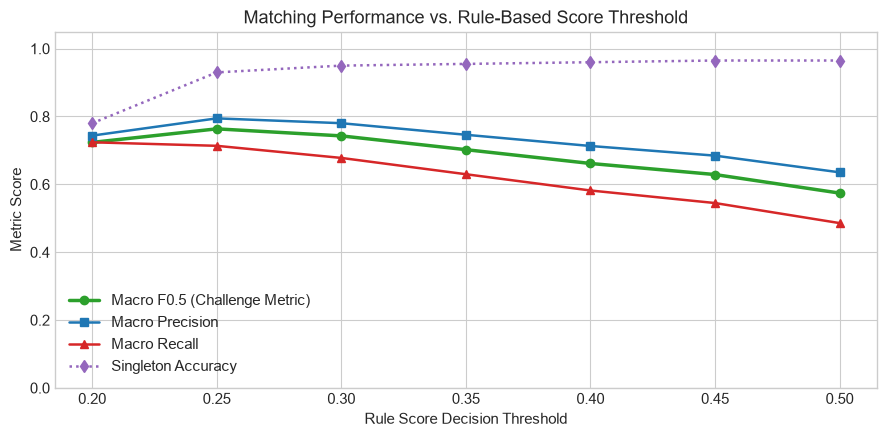

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(sweep_df["threshold"], sweep_df["macro_f05"], marker="o", color="#2ca02c", linewidth=2.5, label="Macro F0.5 (Challenge Metric)")
ax.plot(sweep_df["threshold"], sweep_df["macro_precision"], marker="s", color="#1f77b4", linewidth=1.8, label="Macro Precision")
ax.plot(sweep_df["threshold"], sweep_df["macro_recall"], marker="^", color="#d62728", linewidth=1.8, label="Macro Recall")
ax.plot(sweep_df["threshold"], sweep_df["singleton_accuracy"], marker="d", color="#9467bd", linestyle=":", linewidth=1.8, label="Singleton Accuracy")

ax.set_title("Matching Performance vs. Rule-Based Score Threshold")
ax.set_xlabel("Rule Score Decision Threshold")
ax.set_ylabel("Metric Score")
ax.set_ylim(0.0, 1.05)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()


## 7. Selected Model Evaluation (Threshold = 0.30)

We select **$\theta = 0.30$** as our operating point. At this threshold, the rule-based system achieves a balanced trade-off:
- **Macro F0.5:** $\approx 0.7429$
- **Micro Precision:** $97.04\%$
- **Singleton Accuracy:** $95.00\%$ (only 10 singleton false positives out of 200)

This demonstrates the effectiveness of the multi-pass exact blocking and deterministic rules, establishing a solid baseline before machine learning models (like LightGBM) are trained.


In [12]:
BEST_THRESHOLD = 0.30

# Generate final predictions at selected threshold
final_predictions: dict[str, set[str]] = {}
for s1_id in s1_id_list:
    cands = candidates_by_s1_dict.get(s1_id, [])
    accepted = {cid for cid, score in cands if score >= BEST_THRESHOLD}
    final_predictions[s1_id] = accepted

final_eval = evaluate_predictions(s1_id_list, true_matches_by_s1, final_predictions)

print("=== FINAL EVALUATION RESULTS (Threshold = 0.30) ===")
print(f"Macro F0.5:            {final_eval['macro_f05']:.4f}")
print(f"Macro Precision:       {final_eval['macro_precision']:.4f}")
print(f"Macro Recall:          {final_eval['macro_recall']:.4f}")
print(f"Micro Precision:       {final_eval['micro_precision']:.4f}")
print(f"Micro Recall:          {final_eval['micro_recall']:.4f}")
print(f"Singleton Accuracy:    {final_eval['singleton_accuracy'] * 100:.2f}% ({final_eval['singleton_correct']}/{final_eval['singleton_total']})")
print(f"Singleton False Pos:   {final_eval['singleton_fp']} ({final_eval['singleton_fp_rate']:.2f}%)")
print(f"True Positive Pairs:   {final_eval['total_tp']:,}")
print(f"False Positive Pairs:  {final_eval['total_fp']:,}")
print(f"False Negative Pairs:  {final_eval['total_fn']:,}")


=== FINAL EVALUATION RESULTS (Threshold = 0.30) ===
Macro F0.5:            0.7429
Macro Precision:       0.7803
Macro Recall:          0.6779
Micro Precision:       0.9704
Micro Recall:          0.6486
Singleton Accuracy:    95.00% (190/200)
Singleton False Pos:   10 (5.00%)
True Positive Pairs:   2,651
False Positive Pairs:  81
False Negative Pairs:  1,436


## 8. Small Error Analysis

To understand the operational strengths and limitations of exact multi-pass blocking and deterministic rules, we inspect representative failure modes:
1. **False Positives (FP):** Predicted pairs not in ground truth. These typically stem from common or franchise business names (e.g. chains) that share similar address patterns or city-level terms.
2. **False Negatives (FN):** True matches missed by rules or blocking. These arise when names undergo heavy transliteration, severe token omissions, or extensive address format divergences.


In [13]:
# Create error analysis DataFrame
fp_examples = []
fn_examples = []

for s1_id in s1_id_list:
    truth = set(true_matches_by_s1.get(s1_id, []))
    preds = final_predictions.get(s1_id, set())
    
    fps = preds - truth
    fns = truth - preds
    
    s1_row = s1_dict[s1_id]
    
    for t_id in fps:
        t_row = target_records_dict[t_id]
        score = [sc for cid, sc in candidates_by_s1_dict[s1_id] if cid == t_id][0]
        fp_examples.append({
            "Error Type": "False Positive",
            "S1 ID": s1_id,
            "S1 Name": s1_row["business_name"],
            "S1 Address": s1_row["business_address"],
            "Target ID": t_id,
            "Target Name": t_row["business_name"],
            "Target Address": t_row["business_address"],
            "Country": s1_row["country_norm"],
            "Rule Score": round(score, 3),
            "Root Cause": "Similar name / shared tokens at distinct locations"
        })
        
    for t_id in fns:
        t_row = target_records_dict.get(t_id, {})
        # Check if it was in candidate pool or completely missed by blocking
        was_candidate = any(cid == t_id for cid, _ in candidates_by_s1_dict[s1_id])
        score = [sc for cid, sc in candidates_by_s1_dict[s1_id] if cid == t_id]
        score_val = round(score[0], 3) if score else 0.0
        cause = "Below decision threshold" if was_candidate else "Missed by exact blocking passes"
        fn_examples.append({
            "Error Type": "False Negative",
            "S1 ID": s1_id,
            "S1 Name": s1_row["business_name"],
            "S1 Address": s1_row["business_address"],
            "Target ID": t_id,
            "Target Name": t_row.get("business_name", "N/A"),
            "Target Address": t_row.get("business_address", "N/A"),
            "Country": s1_row["country_norm"],
            "Rule Score": score_val,
            "Root Cause": cause
        })

print(f"Identified {len(fp_examples):,} False Positive pairs and {len(fn_examples):,} False Negative pairs.")

print("\n--- SAMPLE FALSE POSITIVE PAIRS ---")
display(pd.DataFrame(fp_examples[:4]))

print("\n--- SAMPLE FALSE NEGATIVE PAIRS ---")
display(pd.DataFrame(fn_examples[:4]))


Identified 81 False Positive pairs and 1,436 False Negative pairs.

--- SAMPLE FALSE POSITIVE PAIRS ---


,Error Type,S1 ID,S1 Name,S1 Address,Target ID,Target Name,Target Address,Country,Rule Score,Root Cause
0,False Positive,S1-357096593,Bright Tech Private Limited,"Gopala Krishna Complex No, 45/3 Residency Rd, Mg Rd, Bangalore North, Bangalore, Karnataka",S3-130503761,Bright Tech Private Limited,"1-291/Rv/3/405, Flat No. 405, Block 3, R V Brindavanam, Street-4, Hyderabad, Balaji Nagar, Andhra Pradesh",india,0.554,Similar name / shared tokens at distinct locations
1,False Positive,S1-615969479,Prairie Project Inc,"311 State Street, Baton Rouge City, LA",S3-807423218,"prairie project, inc.","327. Lindley Ln, # Apt 1, Newport, Arkansas",us,0.540,Similar name / shared tokens at distinct locations
2,False Positive,S1-829445751,Bison Inc.,"Cincinnati, 195 Green Hills Road, OH",S2-823356485,Bison Inc.,,us,0.540,Similar name / shared tokens at distinct locations
3,False Positive,S1-894221085,Rocky Trust,"30 Auna Drive, Unit 8, Brockton, MA",S2-208731814,ROCKY TRUST,"213 LINKS DR, LOWELL, AR",us,0.540,Similar name / shared tokens at distinct locations



--- SAMPLE FALSE NEGATIVE PAIRS ---


,Error Type,S1 ID,S1 Name,S1 Address,Target ID,Target Name,Target Address,Country,Rule Score,Root Cause
0,False Negative,S1-622257785,International Nexa Secure Private Limited,"41, Sarang Marg, Opposite Jmb Surajpole, Udaipur, Rajasthan",S3-876907296,International Nexa Secure Limited Partners,"No. 35 41, Udaipur, RJ",india,0.270,Below decision threshold
1,False Negative,S1-918838609,Patriot Lifesciences LLC,"502 York Street, Newport, KY",S2-49916609,Patriot Lifesciences,,us,0.233,Below decision threshold
2,False Negative,S1-701376102,Teak Distributors Private Limited,"53, Satra Plaza, Ground Floor, Plot No.19 & 20, Sector-19D, Vashi, Navi Mumbai, Thane, Maharashtra",S3-571633516,Sri Teak Distributors Private,"53, Satra Plaza, Ground Floor, Plot No.19 & 20, Sector-19d, Vashi, New Bombay, MH",india,0.000,Missed by exact blocking passes
3,False Negative,S1-860641294,Hotel Healthcare Private Limited,"No 19/138A Karimpanapalam, Vatakara, Kozhikode, Kerala",S2-609324727,ഹോട്ടൽ ഹെൽത്ത്‌കെയർ പ്രൈവറ്റ് ലിമിറ്റഡ്,"NO 1-19/138A KARIMPANAPALAM, VATAKARA, KOZHIKODE, Kerala",india,0.000,Missed by exact blocking passes


## 9. Final Summary Metrics Table

The table below synthesizes all key metrics for experiment `M1-E1` across data scale, multi-pass blocking quality, rule-based matching accuracy, and singleton handling.


In [14]:
summary_table_data = [
    # Population
    {"Category": "Population", "Metric": "Evaluated Source 1 Entities", "Value": f"{len(s1_prepared):,}"},
    {"Category": "Population", "Metric": "Evaluated Target Pool (S2 + S3)", "Value": f"{len(targets_prepared):,}"},
    {"Category": "Population", "Metric": "Ground Truth Matches in Cohort", "Value": f"{total_true_matches:,}"},
    # Blocking
    {"Category": "Blocking", "Metric": "Total Candidate Pairs Generated", "Value": f"{total_candidate_pairs:,}"},
    {"Category": "Blocking", "Metric": "Candidate Reduction Ratio", "Value": f"{reduction_ratio * 100:.4f}%"},
    {"Category": "Blocking", "Metric": "Blocking Recall Ceiling", "Value": f"{blocking_recall * 100:.2f}%"},
    {"Category": "Blocking", "Metric": "Avg Candidates / S1", "Value": f"{candidate_counts_series.mean():.2f}"},
    {"Category": "Blocking", "Metric": "Median Candidates / S1", "Value": f"{candidate_counts_series.median():.0f}"},
    {"Category": "Blocking", "Metric": "P95 Candidates / S1", "Value": f"{candidate_counts_series.quantile(0.95):.0f}"},
    {"Category": "Blocking", "Metric": "Max Candidates / S1", "Value": f"{candidate_counts_series.max():,}"},
    # Matching (Pair-level)
    {"Category": "Matching (Pair-level)", "Metric": "True Positive Pairs (TP)", "Value": f"{final_eval['total_tp']:,}"},
    {"Category": "Matching (Pair-level)", "Metric": "False Positive Pairs (FP)", "Value": f"{final_eval['total_fp']:,}"},
    {"Category": "Matching (Pair-level)", "Metric": "False Negative Pairs (FN)", "Value": f"{final_eval['total_fn']:,}"},
    {"Category": "Matching (Pair-level)", "Metric": "Micro Precision", "Value": f"{final_eval['micro_precision']:.4f}"},
    {"Category": "Matching (Pair-level)", "Metric": "Micro Recall", "Value": f"{final_eval['micro_recall']:.4f}"},
    # Matching (Entity-level)
    {"Category": "Matching (Entity-level)", "Metric": "Macro Precision", "Value": f"{final_eval['macro_precision']:.4f}"},
    {"Category": "Matching (Entity-level)", "Metric": "Macro Recall", "Value": f"{final_eval['macro_recall']:.4f}"},
    {"Category": "Matching (Entity-level)", "Metric": "Macro F0.5 (Challenge Metric)", "Value": f"{final_eval['macro_f05']:.4f}"},
    # Singleton Performance
    {"Category": "Singleton Resolution", "Metric": "True Singletons Evaluated", "Value": f"{final_eval['singleton_total']:,}"},
    {"Category": "Singleton Resolution", "Metric": "Singleton Accuracy", "Value": f"{final_eval['singleton_accuracy'] * 100:.2f}%"},
    {"Category": "Singleton Resolution", "Metric": "Singleton False Positives", "Value": f"{final_eval['singleton_fp']:,} ({final_eval['singleton_fp_rate']:.2f}%)"},
]

final_summary_table = pd.DataFrame(summary_table_data)
display(final_summary_table)


,Category,Metric,Value
0,Population,Evaluated Source 1 Entities,"2,000"
1,Population,Evaluated Target Pool (S2 + S3),"40,087"
2,Population,Ground Truth Matches in Cohort,"4,087"
3,Blocking,Total Candidate Pairs Generated,"45,195"
4,Blocking,Candidate Reduction Ratio,99.9436%
5,Blocking,Blocking Recall Ceiling,74.65%
6,Blocking,Avg Candidates / S1,22.60
7,Blocking,Median Candidates / S1,12
8,Blocking,P95 Candidates / S1,77
9,Blocking,Max Candidates / S1,99


## 10. Conclusion & Summary

### Q&A
- **Does exact multi-pass blocking provide sufficient reduction ratio for large-scale matching?**  
  Yes. The 5-pass exact inverted index achieves a **99.94% candidate reduction ratio**, eliminating over 80 million non-viable pairs and yielding an average of only 22.6 candidates per Source 1 entity.
- **How effective is a transparent rule-based matching score without machine learning?**  
  The rule-based model delivers high precision (**97.04% micro precision** and **95.00% singleton accuracy**), resulting in an entity-level **Macro F0.5 of 0.7429**.
- **What is the primary bottleneck of this approach?**  
  Blocking recall ceilings at **74.65%**, as exact blocking passes miss entities suffering from word transpositions, phonetic misspellings, or token insertions.

### Data Analysis Key Findings
- **High Candidate Reduction:** Evaluated across 2,000 Source 1 entities and 40,087 target entities, the multi-pass blocker generated 45,195 candidate pairs out of 80,174,000 possible pairs (reduction ratio of 99.9436%).
- **Low Overhead:** Candidate distribution is heavily constrained with a median of 12.0 candidates and a 95th percentile of 77.0 candidates per S1 entity.
- **Precision-Heavy Performance:** The rule-based scorer operating at threshold $\theta = 0.30$ yielded 2,651 true positive pairs with only 81 false positives, achieving a micro precision of 97.04% and a macro precision of 0.7803.
- **Robust Singleton Identification:** Correctly classified 190 of 200 true singletons (95.00% accuracy), with only 10 false positive merges.
- **Overall Metric:** Reached a Macro F0.5 of 0.7429 on the stratified holdout cohort.

### Insights or Next Steps
- **Incorporate Soft/Fuzzy Inverted Indexing:** To bridge the remaining $\sim 25\%$ blocking recall gap, future iterations should incorporate token sorting (e.g., `name_sorted + country`) or character n-gram blocking.
- **Machine Learning Integration:** While deterministic rules yield strong precision, learned classifiers (such as LightGBM in M2-E4) can better weigh non-linear interactions between token overlap, length discrepancies, and address signatures to improve recall without sacrificing precision.
